## Libraries Import and Environment Setup


In [2]:
# TensorFlow / Keras — deep learning model banane ke liye
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Numerical + visualization
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluation metrics
from sklearn.metrics import classification_report, confusion_matrix

# Reproducibility — har baar same results ke liye
import random
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU Available:", len(tf.config.list_physical_devices("GPU")) > 0)


TensorFlow version: 2.21.0
GPU Available: False


##  CIFAR-10 Dataset Load

In [3]:
# CIFAR-10 load — pehli baar internet se download hoga
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()



In [4]:

# Labels abhi (N, 1) shape mein hain — flatten kar dete hain
y_train = y_train.flatten()
y_test = y_test.flatten()

# Class names (index 0–9)
CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Training data shape:", x_train.shape)   # (50000, 32, 32, 3)
print("Testing data shape:", x_test.shape)     # (10000, 32, 32, 3)
print("Labels (unique):", np.unique(y_train))
print("Class names:", CLASS_NAMES)

Training data shape: (50000, 32, 32, 3)
Testing data shape: (10000, 32, 32, 3)
Labels (unique): [0 1 2 3 4 5 6 7 8 9]
Class names: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Data Visualization


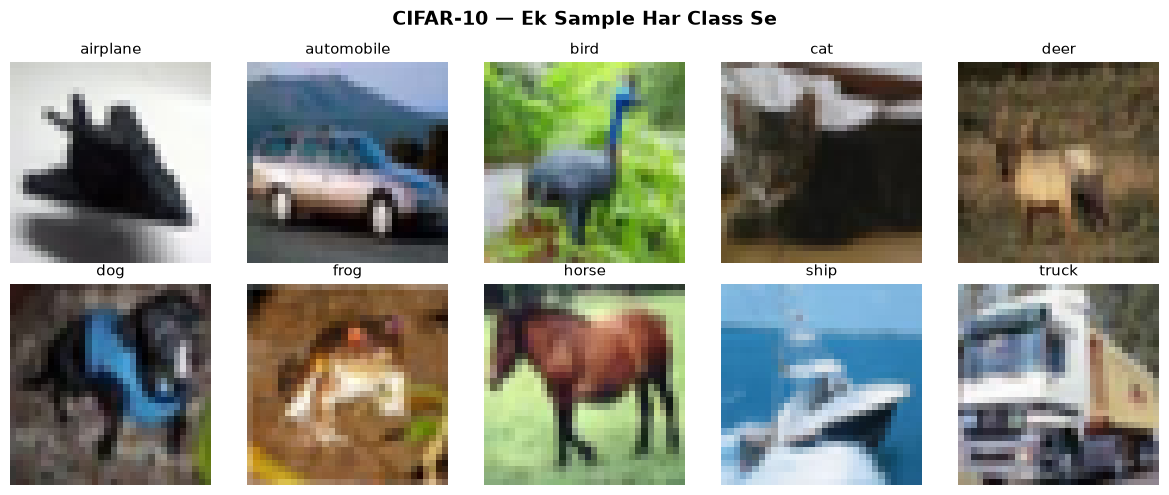

In [5]:
# Har class se ek sample image dikhate hain
plt.figure(figsize=(12, 5))
for class_id in range(10):
    # Us class ki pehli image dhoondo
    idx = np.where(y_train == class_id)[0][0]
    plt.subplot(2, 5, class_id + 1)
    plt.imshow(x_train[idx])
    plt.title(CLASS_NAMES[class_id], fontsize=11)
    plt.axis("off")
plt.suptitle("CIFAR-10 — Ek Sample Har Class Se", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


C:\Users\AM BUSINESS 99\AppData\Local\Temp\ipykernel_5340\295195655.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[CLASS_NAMES[i] for i in unique], y=counts, palette="viridis")


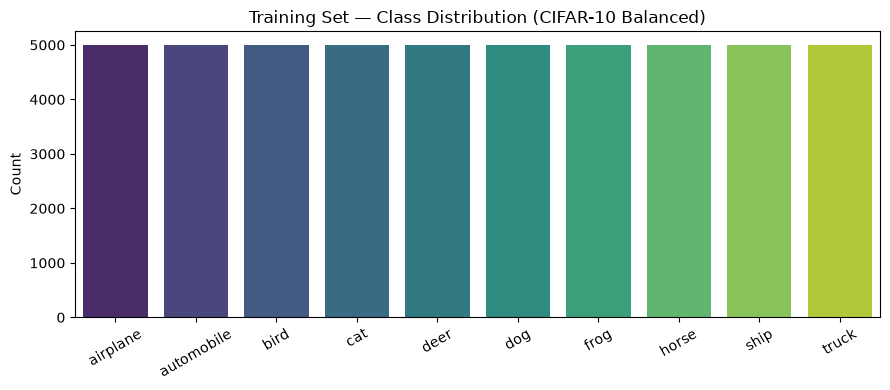

Har class roughly 5000 images — balanced dataset.


In [6]:
# Class distribution check — balanced hai ya nahi
unique, counts = np.unique(y_train, return_counts=True)
plt.figure(figsize=(9, 4))
sns.barplot(x=[CLASS_NAMES[i] for i in unique], y=counts, palette="viridis")
plt.title("Training Set — Class Distribution (CIFAR-10 Balanced)")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Har class roughly 5000 images — balanced dataset.")


## Preprocessing

In [7]:
# 0–255 → 0–1 normalize (training stable hoti hai)
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Train min/max after normalize:", x_train.min(), x_train.max())
print("Train shape (ready for CNN):", x_train.shape)  # (50000, 32, 32, 3)


Train min/max after normalize: 0.0 1.0
Train shape (ready for CNN): (50000, 32, 32, 3)


## Convolution Layer


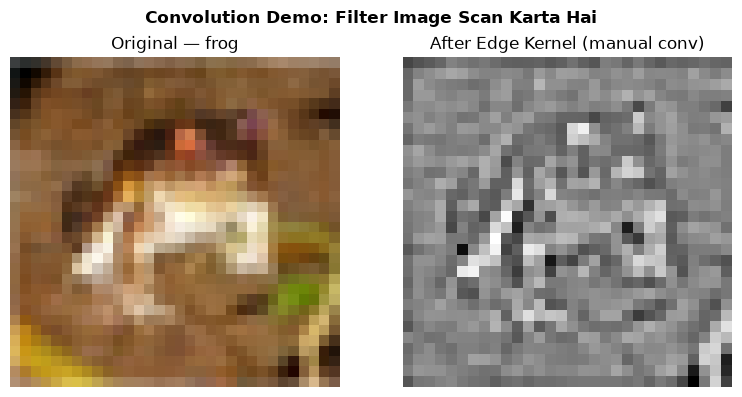

Roman Urdu: Filter chhote window (3×3) se slide karta hai aur local pattern (edge) detect karta hai.


In [8]:
# Simple Sobel-like edge kernel (3×3)
edge_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

def apply_kernel_rgb(img, kernel):
    """Har channel pe alag kernel apply karke average lete hain (demo ke liye)."""
    h, w, c = img.shape
    kh, kw = kernel.shape
    out = np.zeros((h - kh + 1, w - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            # 3 channels ka weighted sum
            patch = img[i:i+kh, j:j+kw, :]
            val = 0.0
            for ch in range(c):
                val += np.sum(patch[:, :, ch] * kernel)
            out[i, j] = val / c
    return out

# Ek sample image pe kernel lagao
sample_img = x_train[0]  # pehli train image
edge_map = apply_kernel_rgb(sample_img, edge_kernel)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample_img)
axes[0].set_title(f"Original — {CLASS_NAMES[y_train[0]]}")
axes[0].axis("off")
axes[1].imshow(edge_map, cmap="gray")
axes[1].set_title("After Edge Kernel (manual conv)")
axes[1].axis("off")
plt.suptitle("Convolution Demo: Filter Image Scan Karta Hai", fontweight="bold")
plt.tight_layout()
plt.show()

print("Roman Urdu: Filter chhote window (3×3) se slide karta hai aur local pattern (edge) detect karta hai.")


## 7. Data Augmentation — Overfitting Kam Karne Ka Tarika

CIFAR-10 pe pure 50k images bhi limited hain. Augmentation (random flip, shift, rotation) se model zyada robust banta hai.


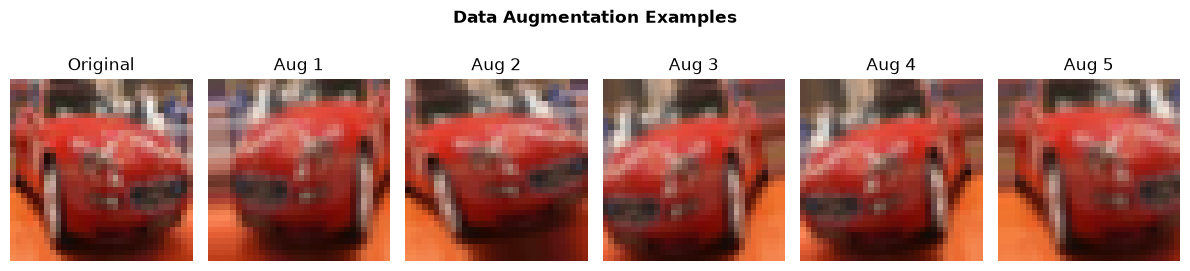

In [9]:
# ImageDataGenerator — training ke dauran on-the-fly augment
datagen = ImageDataGenerator(
    rotation_range=15,          # ±15 degree rotate
    width_shift_range=0.1,      # horizontal shift
    height_shift_range=0.1,     # vertical shift
    horizontal_flip=True,       # left-right flip (objects ke liye natural)
    zoom_range=0.1              # thoda zoom in/out
)

# Visualize augmentation on one image
sample = x_train[5:6]  # batch of 1
aug_iter = datagen.flow(sample, batch_size=1)

plt.figure(figsize=(12, 3))
plt.subplot(1, 6, 1)
plt.imshow(sample[0])
plt.title("Original")
plt.axis("off")
for i in range(5):
    aug_img = next(aug_iter)[0]
    plt.subplot(1, 6, i + 2)
    plt.imshow(aug_img)
    plt.title(f"Aug {i+1}")
    plt.axis("off")
plt.suptitle("Data Augmentation Examples", fontweight="bold")
plt.tight_layout()
plt.show()


## 8. CNN Model Architecture (From Scratch)

Hum ek modern-style small CNN banate hain:
- **Conv blocks** with BatchNorm + ReLU
- **MaxPooling** for downsampling
- **Dropout** for regularization
- **Dense head** for 10-class classification

Yeh architecture MNIST wale simple CNN se deeper aur regularized hai kyunke CIFAR-10 zyada complex hai.


In [10]:
def build_cifar10_cnn(input_shape=(32, 32, 3), num_classes=10):
    """
    CIFAR-10 ke liye from-scratch CNN.
    Har block: Conv → BatchNorm → ReLU (do baar) → MaxPool → Dropout
    """
    model = models.Sequential(name="CIFAR10_CNN")

    # ----- Block 1: 32 filters -----
    model.add(layers.Conv2D(32, (3, 3), padding="same", input_shape=input_shape, name="conv1_1"))
    model.add(layers.BatchNormalization(name="bn1_1"))
    model.add(layers.Activation("relu", name="relu1_1"))
    model.add(layers.Conv2D(32, (3, 3), padding="same", name="conv1_2"))
    model.add(layers.BatchNormalization(name="bn1_2"))
    model.add(layers.Activation("relu", name="relu1_2"))
    model.add(layers.MaxPooling2D((2, 2), name="pool1"))   # 32→16
    model.add(layers.Dropout(0.25, name="drop1"))

    # ----- Block 2: 64 filters -----
    model.add(layers.Conv2D(64, (3, 3), padding="same", name="conv2_1"))
    model.add(layers.BatchNormalization(name="bn2_1"))
    model.add(layers.Activation("relu", name="relu2_1"))
    model.add(layers.Conv2D(64, (3, 3), padding="same", name="conv2_2"))
    model.add(layers.BatchNormalization(name="bn2_2"))
    model.add(layers.Activation("relu", name="relu2_2"))
    model.add(layers.MaxPooling2D((2, 2), name="pool2"))   # 16→8
    model.add(layers.Dropout(0.25, name="drop2"))

    # ----- Block 3: 128 filters -----
    model.add(layers.Conv2D(128, (3, 3), padding="same", name="conv3_1"))
    model.add(layers.BatchNormalization(name="bn3_1"))
    model.add(layers.Activation("relu", name="relu3_1"))
    model.add(layers.Conv2D(128, (3, 3), padding="same", name="conv3_2"))
    model.add(layers.BatchNormalization(name="bn3_2"))
    model.add(layers.Activation("relu", name="relu3_2"))
    model.add(layers.MaxPooling2D((2, 2), name="pool3"))   # 8→4
    model.add(layers.Dropout(0.25, name="drop3"))

    # ----- Classifier head -----
    model.add(layers.Flatten(name="flatten"))
    model.add(layers.Dense(256, name="dense1"))
    model.add(layers.BatchNormalization(name="bn_dense"))
    model.add(layers.Activation("relu", name="relu_dense"))
    model.add(layers.Dropout(0.5, name="drop_dense"))
    model.add(layers.Dense(num_classes, activation="softmax", name="output"))

    return model

model = build_cifar10_cnn()
model.summary()


c:\Users\AM BUSINESS 99\Desktop\deep learning\env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "CIFAR10_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1_1 (Conv2D)                │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_1 (BatchNormalization)      │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_1 (Activation)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_2 (BatchNormalization)      │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_2 (Activation)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_1 (BatchNormalization)      │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2_1 (Activation)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_2 (Conv2D)                │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_2 (BatchNormalization)      │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2_2 (Activation)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_1 (Conv2D)                │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3_1 (BatchNormalization)      │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3_1 (Activation)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_2 (Conv2D)                │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3_2 (BatchNormalization)      │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3_2 (Activation)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (Dropout)                 │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             

 Total params: 816,938 (3.12 MB)

 Trainable params: 815,530 (3.11 MB)

 Non-trainable params: 1,408 (5.50 KB)

**Roman Urdu explanation of layers:**
- **Conv2D(32, 3×3, same):** 32 filters, har filter 3×3 window se image scan karta hai; `same` padding se size same rehta hai.
- **BatchNormalization:** Har batch ke andar activations ko normalize karta hai → training tez aur stable.
- **ReLU:** Negative values zero → non-linearity (bina iske deep network linear ban jata).
- **MaxPooling2D(2×2):** 2×2 window se max value → spatial size aadha, computation kam, translation invariance.
- **Dropout:** Training mein randomly neurons off → overfitting kam.
- **Flatten + Dense:** Feature maps ko vector bana ke final 10-class probabilities (softmax).


## 9. Compile + Callbacks


In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",   # labels integers hain (0–9)
    metrics=["accuracy"]
)

# Callbacks — industry style training control
early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint = callbacks.ModelCheckpoint(
    "best_cifar10_cnn.keras",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)


## 10. Train the Model

Augmentation ke sath fit karte hain. Validation ke liye original (non-augmented) test split use karenge (classroom demo ke liye test set ko val bhi bana rahe hain; production mein alag val split banayein).


In [12]:
BATCH_SIZE = 64
EPOCHS = 25   # EarlyStopping se pehle ruk sakta hai

# Augmented training generator
train_gen = datagen.flow(x_train, y_train, batch_size=BATCH_SIZE, seed=SEED)

history = model.fit(
    train_gen,
    epochs=EPOCHS,
    steps_per_epoch=len(x_train) // BATCH_SIZE,
    validation_data=(x_test, y_test),
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)


Epoch 1/25
781/781 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - accuracy: 0.4267 - loss: 1.6044
Epoch 1: val_accuracy improved from None to 0.52490, saving model to best_cifar10_cnn.keras

Epoch 1: finished saving model to best_cifar10_cnn.keras
781/781 ━━━━━━━━━━━━━━━━━━━━ 225s 275ms/step - accuracy: 0.4267 - loss: 1.6044 - val_accuracy: 0.5249 - val_loss: 1.3210 - learning_rate: 0.0010
Epoch 2/25
  1/781 ━━━━━━━━━━━━━━━━━━━━ 5:13 402ms/step - accuracy: 0.5625 - loss: 1.1351

c:\Users\AM BUSINESS 99\Desktop\deep learning\env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_accuracy improved from 0.52490 to 0.52870, saving model to best_cifar10_cnn.keras

Epoch 2: finished saving model to best_cifar10_cnn.keras
781/781 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.5625 - loss: 1.1351 - val_accuracy: 0.5287 - val_loss: 1.2964 - learning_rate: 0.0010
Epoch 3/25
781/781 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/step - accuracy: 0.5856 - loss: 1.1605
Epoch 3: val_accuracy improved from 0.52870 to 0.59820, saving model to best_cifar10_cnn.keras

Epoch 3: finished saving model to best_cifar10_cnn.keras
781/781 ━━━━━━━━━━━━━━━━━━━━ 215s 275ms/step - accuracy: 0.5856 - loss: 1.1605 - val_accuracy: 0.5982 - val_loss: 1.2033 - learning_rate: 0.0010
Epoch 4/25
  1/781 ━━━━━━━━━━━━━━━━━━━━ 2:38 204ms/step - accuracy: 0.6562 - loss: 1.0791
Epoch 4: val_accuracy did not improve from 0.59820
781/781 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.6562 - loss: 1.0791 - val_accuracy: 0.5982 - val_loss: 1.2066 - learning_rate: 0.0010
Epoch 5/25
781/781 ━━━━━━━━━━━━━━━━

## 11. Training Curves — Loss & Accuracy


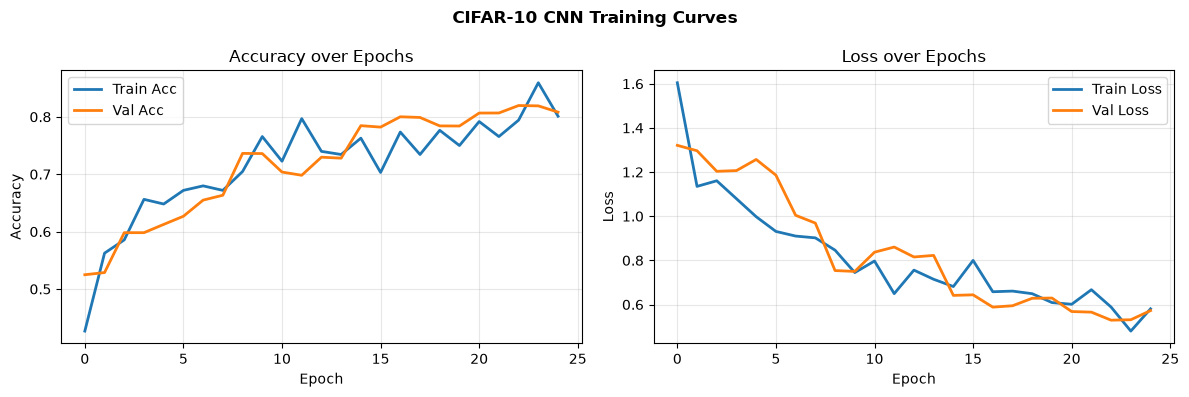

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy
axes[0].plot(history.history["accuracy"], label="Train Acc", linewidth=2)
axes[0].plot(history.history["val_accuracy"], label="Val Acc", linewidth=2)
axes[0].set_title("Accuracy over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(history.history["loss"], label="Train Loss", linewidth=2)
axes[1].plot(history.history["val_loss"], label="Val Loss", linewidth=2)
axes[1].set_title("Loss over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("CIFAR-10 CNN Training Curves", fontweight="bold")
plt.tight_layout()
plt.show()


## 12. Evaluation — Test Set Metrics


In [14]:
# Best weights already restored by EarlyStopping / Checkpoint
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Predictions
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))


Test Loss: 0.5291
Test Accuracy: 81.97%

Classification Report:
              precision    recall  f1-score   support

    airplane       0.84      0.83      0.84      1000
  automobile       0.88      0.94      0.91      1000
        bird       0.85      0.67      0.75      1000
         cat       0.81      0.54      0.65      1000
        deer       0.79      0.81      0.80      1000
         dog       0.82      0.70      0.75      1000
        frog       0.72      0.94      0.82      1000
       horse       0.83      0.91      0.87      1000
        ship       0.90      0.90      0.90      1000
       truck       0.80      0.94      0.86      1000

    accuracy                           0.82     10000
   macro avg       0.82      0.82      0.81     10000
weighted avg       0.82      0.82      0.81     10000



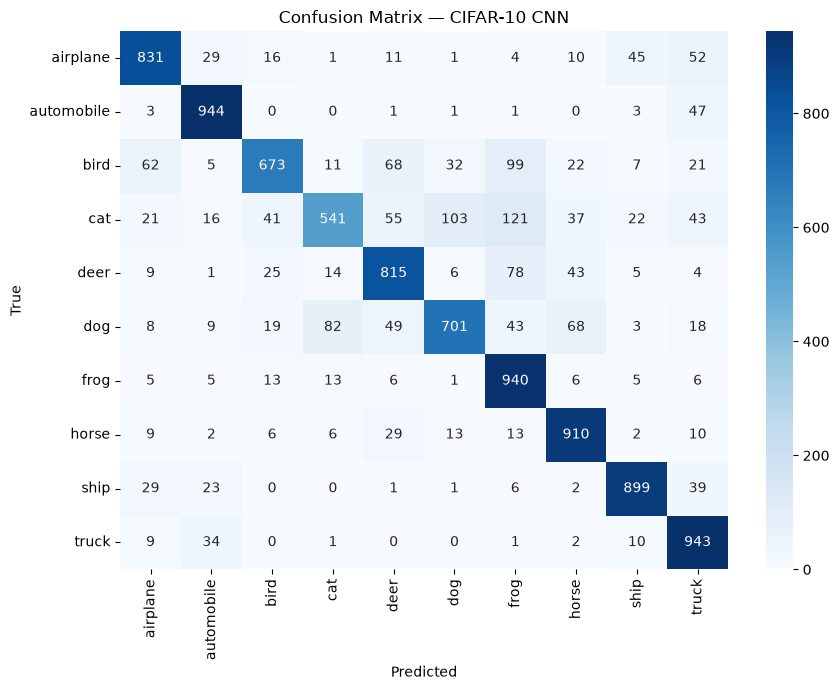

In [15]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix — CIFAR-10 CNN")
plt.tight_layout()
plt.show()


## 13. Per-Class Accuracy Bar Chart


C:\Users\AM BUSINESS 99\AppData\Local\Temp\ipykernel_5340\784920856.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=CLASS_NAMES, y=per_class_acc, palette="coolwarm")


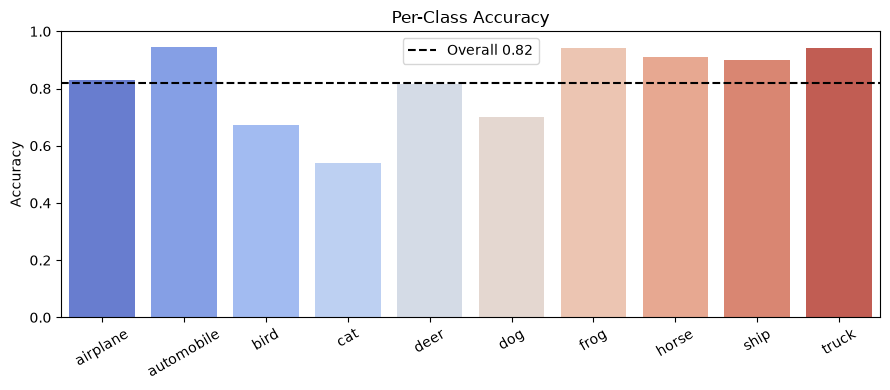

In [16]:
per_class_acc = cm.diagonal() / cm.sum(axis=1)
plt.figure(figsize=(9, 4))
sns.barplot(x=CLASS_NAMES, y=per_class_acc, palette="coolwarm")
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Per-Class Accuracy")
plt.xticks(rotation=30)
plt.axhline(test_acc, color="black", linestyle="--", label=f"Overall {test_acc:.2f}")
plt.legend()
plt.tight_layout()
plt.show()


## 15. Sample Predictions — Correct vs Wrong


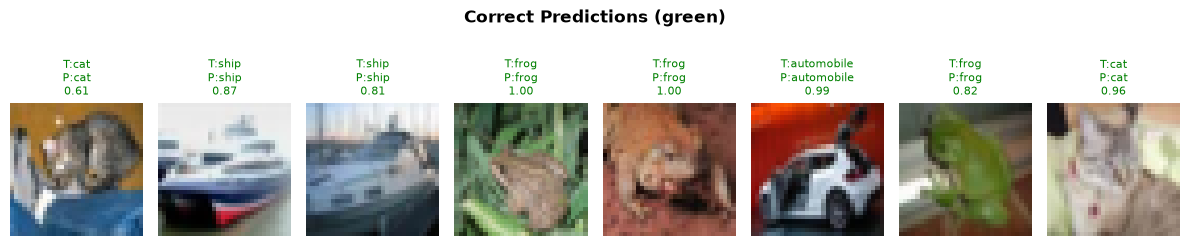

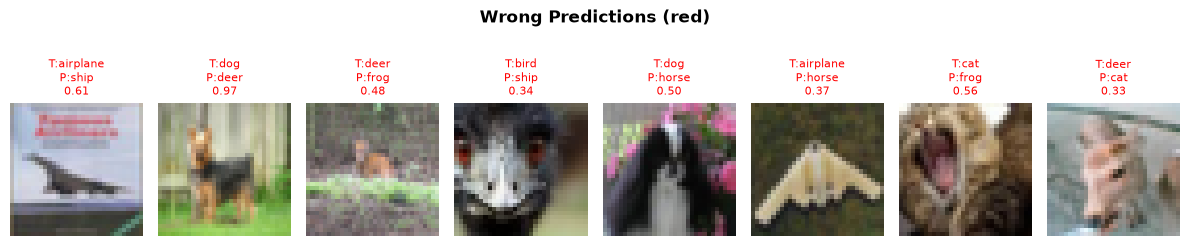

In [18]:
correct = np.where(y_pred == y_test)[0]
wrong = np.where(y_pred != y_test)[0]

def show_predictions(indices, title, n=8):
    plt.figure(figsize=(12, 3))
    for i, idx in enumerate(indices[:n]):
        plt.subplot(1, n, i + 1)
        plt.imshow(x_test[idx])
        true_lbl = CLASS_NAMES[y_test[idx]]
        pred_lbl = CLASS_NAMES[y_pred[idx]]
        conf = y_prob[idx].max()
        color = "green" if true_lbl == pred_lbl else "red"
        plt.title(f"T:{true_lbl}\nP:{pred_lbl}\n{conf:.2f}", color=color, fontsize=8)
        plt.axis("off")
    plt.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()

show_predictions(correct, "Correct Predictions (green)")
show_predictions(wrong, "Wrong Predictions (red)")


## 16. Save Model + Production-Style Inference Function


In [19]:
# Full model save (architecture + weights)
model.save("cifar10_cnn_final.keras")
print("Model saved: cifar10_cnn_final.keras")


Model saved: cifar10_cnn_final.keras


In [20]:
def predict_cifar10(images, model, class_names=CLASS_NAMES):
    """
    Production-style inference.
    images: numpy array of shape (N, 32, 32, 3) with pixel values in 0–255 OR already 0–1.
    Returns dataframe-like dict with predicted class and confidence.
    """
    imgs = np.asarray(images, dtype=np.float32)
    if imgs.max() > 1.5:          # still in 0–255 range
        imgs = imgs / 255.0
    if imgs.ndim == 3:
        imgs = np.expand_dims(imgs, 0)

    probs = model.predict(imgs, verbose=0)
    pred_idx = np.argmax(probs, axis=1)
    conf = np.max(probs, axis=1)

    results = []
    for i in range(len(pred_idx)):
        results.append({
            "predicted_class": class_names[pred_idx[i]],
            "confidence": float(conf[i]),
            "all_probabilities": {class_names[j]: float(probs[i, j]) for j in range(10)}
        })
    return results

# Demo on 5 test images
demo_imgs = x_test[:5] * 255.0   # back to 0–255 style input
preds = predict_cifar10(demo_imgs, model)
for i, p in enumerate(preds):
    print(f"Image {i}: True={CLASS_NAMES[y_test[i]]:12s} | Pred={p['predicted_class']:12s} | Conf={p['confidence']:.3f}")


Image 0: True=cat          | Pred=cat          | Conf=0.613
Image 1: True=ship         | Pred=ship         | Conf=0.871
Image 2: True=ship         | Pred=ship         | Conf=0.808
Image 3: True=airplane     | Pred=ship         | Conf=0.613
Image 4: True=frog         | Pred=frog         | Conf=0.998
